Trials observing 5 Heads : 35,469 / 100,000 (35.47%)
Analytical P(D | 5H)     : 16/17 = 94.12%
Simulated  P(D | 5H)     : 94.14%



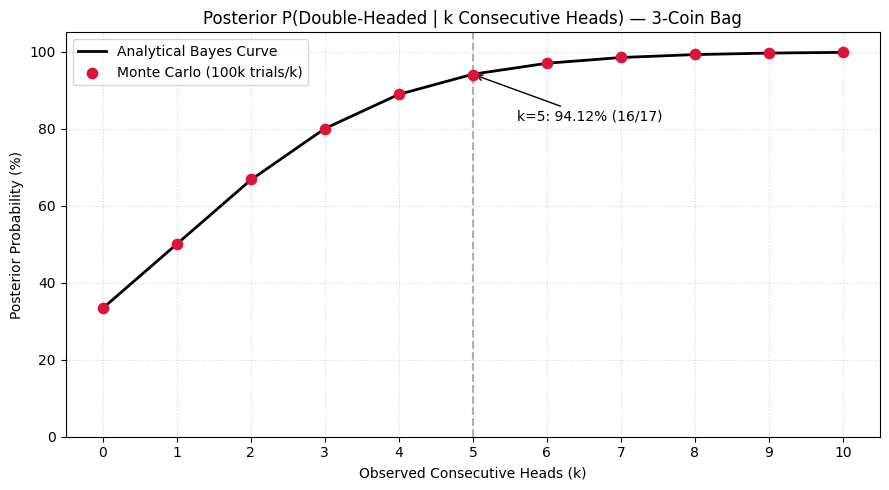

Trials observing 5 Heads : 32,154 / 1,000,000
Analytical P(D | 5H)     : 32/1031 = 3.10%
Simulated  P(D | 5H)     : 3.08%



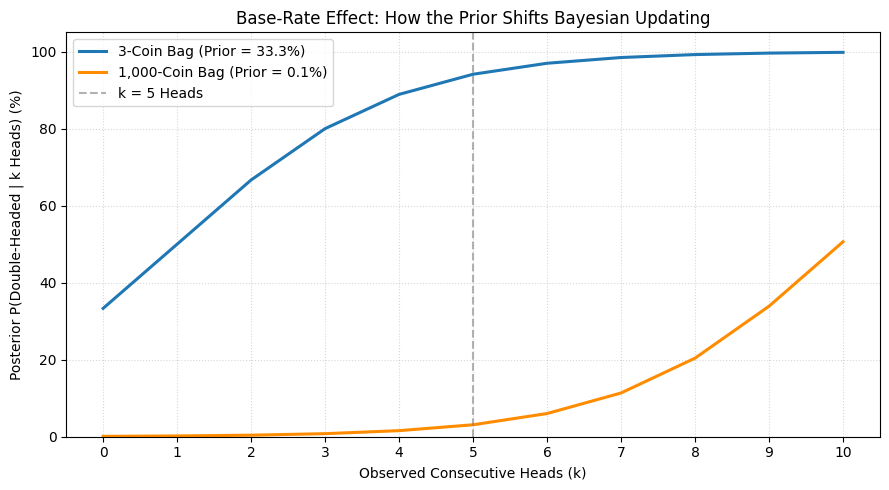

Trials with 5H then 1T   : 1,044
Simulated P(D | 5H, 1T)  : 0.00%


In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

def analytical_posterior(k, n_fair):
    """Exact P(Double-Headed | k consecutive Heads) with 1 double-headed & n_fair fair coins."""
    return 1.0 / (1.0 + n_fair * (0.5 ** k))

def simulate_posterior(k, n_fair, n_trials, rng):
    """Monte Carlo simulation of P(Double-Headed | k consecutive Heads)."""
    total_coins = n_fair + 1
    # Coin 0 = double-headed; coins 1..n_fair = fair
    coin_choice = rng.integers(0, total_coins, size=n_trials)
    is_double = (coin_choice == 0)

    fair_heads = rng.binomial(n=k, p=0.5, size=n_trials)
    heads_count = np.where(is_double, k, fair_heads)

    got_k_heads = (heads_count == k)
    sim_post = is_double[got_k_heads].mean()
    return sim_post, got_k_heads.sum()

n_trials = 100_000
k = 5
n_fair = 2

sim_5h, count_5h = simulate_posterior(k, n_fair, n_trials, rng)
theo_5h = analytical_posterior(k, n_fair)


print(f"Trials observing 5 Heads : {count_5h:,} / {n_trials:,} ({count_5h / n_trials * 100:.2f}%)")
print(f"Analytical P(D | 5H)     : 16/17 = {theo_5h * 100:.2f}%")
print(f"Simulated  P(D | 5H)     : {sim_5h * 100:.2f}%\n")

# Sweep k = 0 to 10: Analytical curve vs. Monte Carlo dots
k_vals = np.arange(0, 11)
theo_curve = [analytical_posterior(kv, n_fair) * 100 for kv in k_vals]
sim_curve = [simulate_posterior(kv, n_fair, n_trials, rng)[0] * 100 for kv in k_vals]

plt.figure(figsize=(9, 5))
plt.plot(k_vals, theo_curve, color='black', linewidth=2, label='Analytical Bayes Curve')
plt.scatter(k_vals, sim_curve, color='crimson', s=55, zorder=5, label='Monte Carlo (100k trials/k)')
plt.axvline(5, color='gray', linestyle='--', alpha=0.6)
plt.annotate(f'k=5: {theo_5h*100:.2f}% (16/17)', xy=(5, theo_5h*100), xytext=(5.6, 82),
             arrowprops=dict(arrowstyle='->', color='black'))

plt.title('Posterior P(Double-Headed | k Consecutive Heads) — 3-Coin Bag')
plt.xlabel('Observed Consecutive Heads (k)')
plt.ylabel('Posterior Probability (%)')
plt.ylim(0, 105)
plt.xticks(k_vals)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 1. Base-Rate Neglect: 999 Fair, 1 Double-Headed (1M trials)
n_trials_rare = 1_000_000
sim_rare, count_rare = simulate_posterior(k=5, n_fair=999, n_trials=n_trials_rare, rng=rng)
theo_rare = analytical_posterior(k=5, n_fair=999)

print(f"Trials observing 5 Heads : {count_rare:,} / {n_trials_rare:,}")
print(f"Analytical P(D | 5H)     : 32/1031 = {theo_rare * 100:.2f}%")
print(f"Simulated  P(D | 5H)     : {sim_rare * 100:.2f}%\n")

# Compare 3-coin vs 1,000-coin Bayesian updating curves
theo_rare_curve = [analytical_posterior(kv, 999) * 100 for kv in k_vals]

plt.figure(figsize=(9, 5))
plt.plot(k_vals, theo_curve, linewidth=2.2, label='3-Coin Bag (Prior = 33.3%)')
plt.plot(k_vals, theo_rare_curve, linewidth=2.2, color='darkorange', label='1,000-Coin Bag (Prior = 0.1%)')
plt.axvline(5, color='gray', linestyle='--', alpha=0.6, label='k = 5 Heads')
plt.title('Base-Rate Effect: How the Prior Shifts Bayesian Updating')
plt.xlabel('Observed Consecutive Heads (k)')
plt.ylabel('Posterior P(Double-Headed | k Heads) (%)')
plt.ylim(0, 105)
plt.xticks(k_vals)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. The 6th-Flip Falsifier (5 Heads followed by 1 Tail)
# Simulate 3-coin bag for 6 flips
coin_6 = rng.integers(0, 3, size=n_trials)
is_double_6 = (coin_6 == 0)
first_5_heads = np.where(is_double_6, 5, rng.binomial(5, 0.5, size=n_trials))
sixth_is_tail = np.where(is_double_6, False, rng.integers(0, 2, size=n_trials) == 0)

mask_5h_1t = (first_5_heads == 5) & sixth_is_tail

print(f"Trials with 5H then 1T   : {mask_5h_1t.sum():,}")
print(f"Simulated P(D | 5H, 1T)  : {is_double_6[mask_5h_1t].mean() * 100:.2f}%")
